# Project Title: Diabetes Risk Analysis and Prediction Using Machine Learning Techniques
**Your Name:** Muhammed Rashid P.

**Date:** October 15, 2026

# Introduction

### Problem Statement
Diabetes is a rapidly growing global health concern. The objective of this project is to analyze a comprehensive health survey dataset and build a machine learning model capable of automatically predicting a patient's diabetes risk level—categorized as **Low**, **Moderate**, or **High**. By feeding the model various health and lifestyle metrics, we aim to create a tool that accurately classifies a patient's risk based on their unique profile.

### Importance
Accurately predicting diabetes risk is crucial for real-world healthcare. If doctors and medical facilities can identify at-risk patients early, they can recommend preventative lifestyle changes or treatments before the disease fully develops. This predictive capability saves lives, improves patient well-being, and reduces long-term financial and operational strain on healthcare systems.

---

# Dataset Overview

* **Source:** `diabetes_risk_prediction_dataset.csv`.
* **Description:** The dataset contains **50,000 samples (patients)** and **42 features (columns)** covering demographics, body measurements, blood test results, lifestyle habits, and risk categories.

In [1]:
import pandas as pd

In [2]:
df = pd.read_csv(r"C:\Users\korad\Downloads\diabetes_risk_prediction_dataset.csv")

In [3]:
df

,Patient_ID,Age,Gender,Country,Height_cm,Weight_kg,BMI,Waist_Circumference_cm,Blood_Glucose,HbA1c,...,PCOS,Medication_Adherence,Work_Type,Residence_Type,Daily_Water_Intake_L,Diabetes_Risk_Score,AI_Health_Recommendation,Doctor_Consultation_Needed,Diabetes_Risk,BMI_CATEGORY
0,1,32.0,Male,Mexico,182.1,65.8,19.8,71.2,88.4,10.4,...,No,Good,Retired,Rural,4.4,60,Healthy Diet Plan,Yes,Moderate,Normal
1,2,42.0,Other,Saudi Arabia,148.5,101.2,45.9,121.8,247.3,11.3,...,Yes,Average,Government,Rural,2.1,99,Begin Diabetes Management Plan,Yes,High,Obese
2,3,89.0,Other,Argentina,158.1,NaN,37.9,131.8,141.9,6.3,...,No,Average,Government,Urban,2.8,80,Strict Blood Sugar Monitoring,Yes,High,Obese
3,4,87.0,Other,United States,190.9,95.9,26.3,99.1,90.1,7.4,...,No,Average,Business,Rural,1.5,82,Begin Diabetes Management Plan,Yes,High,Overweight
4,5,27.0,Other,Australia,156.9,101.9,41.4,77.1,93.8,12.0,...,Yes,Poor,Private,Rural,1.6,93,Begin Diabetes Management Plan,Yes,High,Obese
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,49996,52.0,Female,United Kingdom,153.9,107.4,45.3,75.9,248.8,9.9,...,Yes,Average,Retired,Urban,3.5,86,Consult Endocrinologist Immediately,Yes,High,Obese
49996,49997,53.0,Male,United Kingdom,179.6,64.0,19.8,114.5,198.4,6.3,...,No,Average,Government,Urban,3.4,49,Weight Management Program,No,Moderate,Normal
49997,49998,88.0,Male,Brazil,194.1,65.6,17.4,96.1,118.8,NaN,...,Yes,Poor,Retired,Urban,2.6,100,Begin Diabetes Management Plan,Yes,High,Underweight
49998,49999,23.0,Other,Bangladesh,168.0,73.9,26.2,131.4,139.5,9.2,...,Yes,Good,Private,Urban,2.7,52,Increase Physical Activity,No,Moderate,Overweight


In [4]:
df.shape

(50000, 42)

In [5]:
df.head()

,Patient_ID,Age,Gender,Country,Height_cm,Weight_kg,BMI,Waist_Circumference_cm,Blood_Glucose,HbA1c,...,PCOS,Medication_Adherence,Work_Type,Residence_Type,Daily_Water_Intake_L,Diabetes_Risk_Score,AI_Health_Recommendation,Doctor_Consultation_Needed,Diabetes_Risk,BMI_CATEGORY
0,1,32.0,Male,Mexico,182.1,65.8,19.8,71.2,88.4,10.4,...,No,Good,Retired,Rural,4.4,60,Healthy Diet Plan,Yes,Moderate,Normal
1,2,42.0,Other,Saudi Arabia,148.5,101.2,45.9,121.8,247.3,11.3,...,Yes,Average,Government,Rural,2.1,99,Begin Diabetes Management Plan,Yes,High,Obese
2,3,89.0,Other,Argentina,158.1,NaN,37.9,131.8,141.9,6.3,...,No,Average,Government,Urban,2.8,80,Strict Blood Sugar Monitoring,Yes,High,Obese
3,4,87.0,Other,United States,190.9,95.9,26.3,99.1,90.1,7.4,...,No,Average,Business,Rural,1.5,82,Begin Diabetes Management Plan,Yes,High,Overweight
4,5,27.0,Other,Australia,156.9,101.9,41.4,77.1,93.8,12.0,...,Yes,Poor,Private,Rural,1.6,93,Begin Diabetes Management Plan,Yes,High,Obese


In [6]:
df.tail()

,Patient_ID,Age,Gender,Country,Height_cm,Weight_kg,BMI,Waist_Circumference_cm,Blood_Glucose,HbA1c,...,PCOS,Medication_Adherence,Work_Type,Residence_Type,Daily_Water_Intake_L,Diabetes_Risk_Score,AI_Health_Recommendation,Doctor_Consultation_Needed,Diabetes_Risk,BMI_CATEGORY
49995,49996,52.0,Female,United Kingdom,153.9,107.4,45.3,75.9,248.8,9.9,...,Yes,Average,Retired,Urban,3.5,86,Consult Endocrinologist Immediately,Yes,High,Obese
49996,49997,53.0,Male,United Kingdom,179.6,64.0,19.8,114.5,198.4,6.3,...,No,Average,Government,Urban,3.4,49,Weight Management Program,No,Moderate,Normal
49997,49998,88.0,Male,Brazil,194.1,65.6,17.4,96.1,118.8,NaN,...,Yes,Poor,Retired,Urban,2.6,100,Begin Diabetes Management Plan,Yes,High,Underweight
49998,49999,23.0,Other,Bangladesh,168.0,73.9,26.2,131.4,139.5,9.2,...,Yes,Good,Private,Urban,2.7,52,Increase Physical Activity,No,Moderate,Overweight
49999,50000,24.0,Female,Australia,152.8,94.6,40.5,66.1,123.5,6.8,...,Yes,Good,Retired,Urban,3.9,91,Consult Endocrinologist Immediately,Yes,High,Obese


In [7]:
# Drop irrelevant columns
df = df.drop(columns=['Patient_ID', 'AI_Health_Recommendation', 'Diabetes_Risk_Score'])

In [8]:
df.size

1950000

In [9]:
df.columns

Index(['Age', 'Gender', 'Country', 'Height_cm', 'Weight_kg', 'BMI',
       'Waist_Circumference_cm', 'Blood_Glucose', 'HbA1c',
       'Fasting_Blood_Sugar', 'Insulin_Level', 'Blood_Pressure_Systolic',
       'Blood_Pressure_Diastolic', 'Total_Cholesterol', 'HDL', 'LDL',
       'Triglycerides', 'Heart_Rate', 'Physical_Activity_Level',
       'Exercise_Hours_Per_Week', 'Daily_Walking_Minutes', 'Diet_Quality',
       'Sugar_Intake_Level', 'Sleep_Hours', 'Stress_Level', 'Smoking_Status',
       'Alcohol_Consumption', 'Family_History_Diabetes', 'Hypertension',
       'Heart_Disease', 'Fatty_Liver', 'PCOS', 'Medication_Adherence',
       'Work_Type', 'Residence_Type', 'Daily_Water_Intake_L',
       'Doctor_Consultation_Needed', 'Diabetes_Risk', 'BMI_CATEGORY'],
      dtype='str')

In [10]:
df['Gender'].unique()

<ArrowStringArray>
['Male', 'Other', 'Female']
Length: 3, dtype: str

In [11]:
df['Gender'].value_counts()

Gender
Male      16718
Other     16677
Female    16605
Name: count, dtype: int64

In [12]:
pd.set_option('display.max_columns', None)

In [13]:
df.head()

,Age,Gender,Country,Height_cm,Weight_kg,BMI,Waist_Circumference_cm,Blood_Glucose,HbA1c,Fasting_Blood_Sugar,Insulin_Level,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Total_Cholesterol,HDL,LDL,Triglycerides,Heart_Rate,Physical_Activity_Level,Exercise_Hours_Per_Week,Daily_Walking_Minutes,Diet_Quality,Sugar_Intake_Level,Sleep_Hours,Stress_Level,Smoking_Status,Alcohol_Consumption,Family_History_Diabetes,Hypertension,Heart_Disease,Fatty_Liver,PCOS,Medication_Adherence,Work_Type,Residence_Type,Daily_Water_Intake_L,Doctor_Consultation_Needed,Diabetes_Risk,BMI_CATEGORY
0,32.0,Male,Mexico,182.1,65.8,19.8,71.2,88.4,10.4,149.5,27.4,94,61,138.7,40.1,152.3,250.8,119,Moderate,2.2,106.1,Healthy,Low,7.9,Moderate,Former,Never,Yes,No,Yes,Yes,No,Good,Retired,Rural,4.4,Yes,Moderate,Normal
1,42.0,Other,Saudi Arabia,148.5,101.2,45.9,121.8,247.3,11.3,199.3,18.3,148,100,286.8,35.6,110.4,287.9,59,High,6.3,96.1,Healthy,Low,6.2,Moderate,Current,Frequently,Yes,No,Yes,Yes,Yes,Average,Government,Rural,2.1,Yes,High,Obese
2,89.0,Other,Argentina,158.1,NaN,37.9,131.8,141.9,6.3,219.6,23.9,101,108,129.4,32.1,156.7,329.3,104,High,0.6,68.7,Average,High,4.8,High,Never,Frequently,Yes,No,No,Yes,No,Average,Government,Urban,2.8,Yes,High,Obese
3,87.0,Other,United States,190.9,95.9,26.3,99.1,90.1,7.4,217.7,36.7,120,63,168.2,61.9,63.4,308.8,58,High,7.7,23.1,Average,High,4.2,High,Current,Occasionally,Yes,Yes,No,No,No,Average,Business,Rural,1.5,Yes,High,Overweight
4,27.0,Other,Australia,156.9,101.9,41.4,77.1,93.8,12.0,153.5,22.3,190,90,281.5,37.4,66.5,206.6,104,Moderate,4.7,131.2,Poor,High,9.9,Low,Never,Occasionally,No,Yes,Yes,Yes,Yes,Poor,Private,Rural,1.6,Yes,High,Obese


In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 39 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         49503 non-null  float64
 1   Gender                      50000 non-null  str    
 2   Country                     50000 non-null  str    
 3   Height_cm                   47055 non-null  float64
 4   Weight_kg                   47038 non-null  float64
 5   BMI                         50000 non-null  float64
 6   Waist_Circumference_cm      50000 non-null  float64
 7   Blood_Glucose               49041 non-null  float64
 8   HbA1c                       48026 non-null  float64
 9   Fasting_Blood_Sugar         50000 non-null  float64
 10  Insulin_Level               50000 non-null  float64
 11  Blood_Pressure_Systolic     50000 non-null  int64  
 12  Blood_Pressure_Diastolic    50000 non-null  int64  
 13  Total_Cholesterol           49000 non-null

In [15]:
import numpy as np
num_cols = df.select_dtypes(include = [np.number]).columns.tolist()
str_cols = df.select_dtypes(include = ["str"]).columns.tolist()

print(f"Numeric Columns ({len(num_cols)}):\n{num_cols}\n")
print(f"Categorical columns ({len(str_cols)}):\n{str_cols}\n")

Numeric Columns (20):
['Age', 'Height_cm', 'Weight_kg', 'BMI', 'Waist_Circumference_cm', 'Blood_Glucose', 'HbA1c', 'Fasting_Blood_Sugar', 'Insulin_Level', 'Blood_Pressure_Systolic', 'Blood_Pressure_Diastolic', 'Total_Cholesterol', 'HDL', 'LDL', 'Triglycerides', 'Heart_Rate', 'Exercise_Hours_Per_Week', 'Daily_Walking_Minutes', 'Sleep_Hours', 'Daily_Water_Intake_L']

Categorical columns (19):
['Gender', 'Country', 'Physical_Activity_Level', 'Diet_Quality', 'Sugar_Intake_Level', 'Stress_Level', 'Smoking_Status', 'Alcohol_Consumption', 'Family_History_Diabetes', 'Hypertension', 'Heart_Disease', 'Fatty_Liver', 'PCOS', 'Medication_Adherence', 'Work_Type', 'Residence_Type', 'Doctor_Consultation_Needed', 'Diabetes_Risk', 'BMI_CATEGORY']



In [16]:
df.duplicated().sum()

np.int64(0)

In [17]:
df.isnull().sum()

Age                            497
Gender                           0
Country                          0
Height_cm                     2945
Weight_kg                     2962
BMI                              0
Waist_Circumference_cm           0
Blood_Glucose                  959
HbA1c                         1974
Fasting_Blood_Sugar              0
Insulin_Level                    0
Blood_Pressure_Systolic          0
Blood_Pressure_Diastolic         0
Total_Cholesterol             1000
HDL                           1000
LDL                           1000
Triglycerides                 1000
Heart_Rate                       0
Physical_Activity_Level        500
Exercise_Hours_Per_Week       1992
Daily_Walking_Minutes         1964
Diet_Quality                     0
Sugar_Intake_Level               0
Sleep_Hours                   2017
Stress_Level                     0
Smoking_Status                   0
Alcohol_Consumption              0
Family_History_Diabetes          0
Hypertension        

In [18]:
df_clean = df.copy()

for col in num_cols:
    if df_clean[col].isnull().sum() > 0:
        df_clean[col] = df_clean[col].fillna(df_clean[col].median())


for col in str_cols:
    if df_clean[col].isnull().sum() > 0:
        df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

df_clean.isnull().sum()

Age                           0
Gender                        0
Country                       0
Height_cm                     0
Weight_kg                     0
BMI                           0
Waist_Circumference_cm        0
Blood_Glucose                 0
HbA1c                         0
Fasting_Blood_Sugar           0
Insulin_Level                 0
Blood_Pressure_Systolic       0
Blood_Pressure_Diastolic      0
Total_Cholesterol             0
HDL                           0
LDL                           0
Triglycerides                 0
Heart_Rate                    0
Physical_Activity_Level       0
Exercise_Hours_Per_Week       0
Daily_Walking_Minutes         0
Diet_Quality                  0
Sugar_Intake_Level            0
Sleep_Hours                   0
Stress_Level                  0
Smoking_Status                0
Alcohol_Consumption           0
Family_History_Diabetes       0
Hypertension                  0
Heart_Disease                 0
Fatty_Liver                   0
PCOS    

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
palette = sns.color_palette()

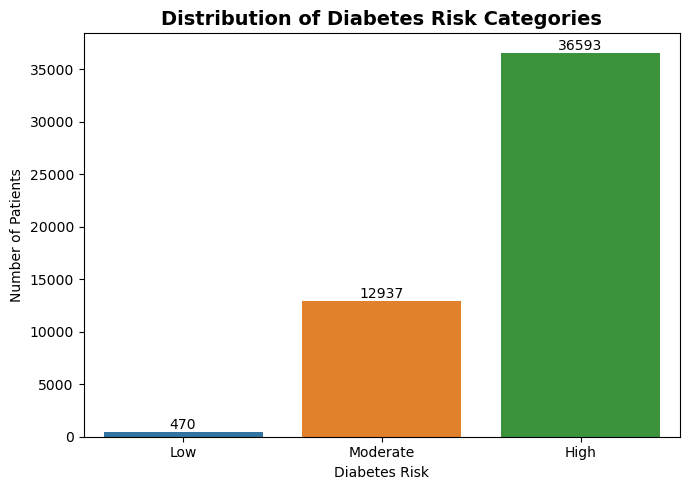

Diabetes_Risk
High        36593
Moderate    12937
Low           470
Name: count, dtype: int64

Percentage split:
Diabetes_Risk
High        73.19
Moderate    25.87
Low          0.94
Name: count, dtype: float64


In [20]:
import warnings
warnings.filterwarnings('ignore')

risk_counts = df_clean["Diabetes_Risk"].value_counts()
risk_order = ["Low", "Moderate", "High"]

plt.figure(figsize=(7, 5))
ax = sns.countplot(x="Diabetes_Risk", data=df_clean, order=risk_order, palette=palette)
plt.title("Distribution of Diabetes Risk Categories", fontsize=14, fontweight="bold")
plt.xlabel("Diabetes Risk")
plt.ylabel("Number of Patients")
for container in ax.containers:
    ax.bar_label(container)
plt.tight_layout()
plt.show()

print(risk_counts)
print("\nPercentage split:")
print((risk_counts / len(df_clean) * 100).round(2))

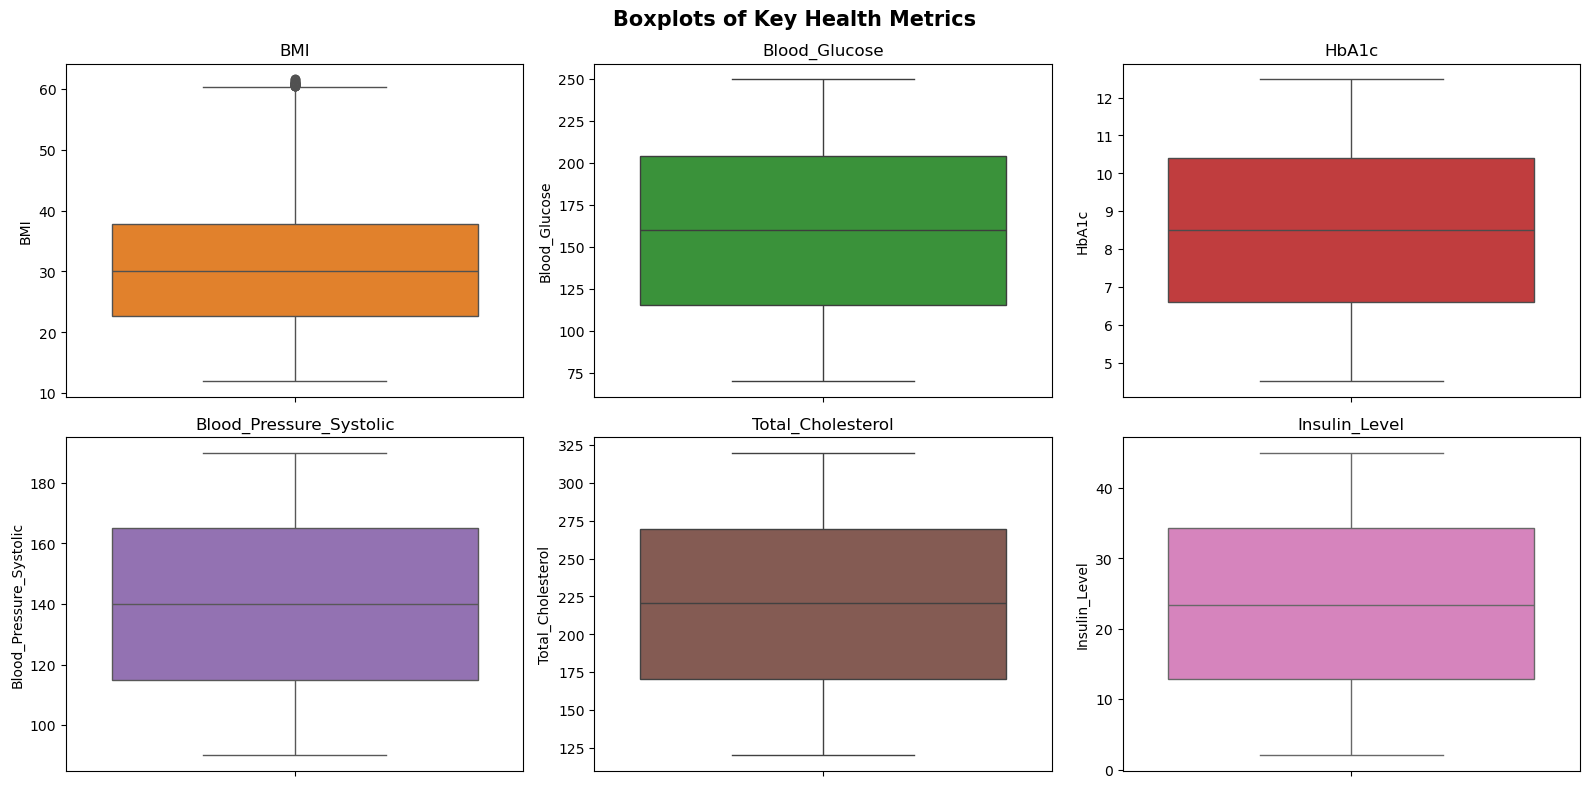

In [21]:
# 2. Box plots for Key Health Metrics
key_metrics = ["BMI", "Blood_Glucose", "HbA1c", "Blood_Pressure_Systolic", "Total_Cholesterol", "Insulin_Level"]
plt.figure(figsize=(16, 8))
for i, col in enumerate(key_metrics, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=df_clean[col], color=palette[i % len(palette)])
    plt.title(col)
plt.suptitle("Boxplots of Key Health Metrics", fontsize=15, fontweight="bold")
plt.tight_layout()

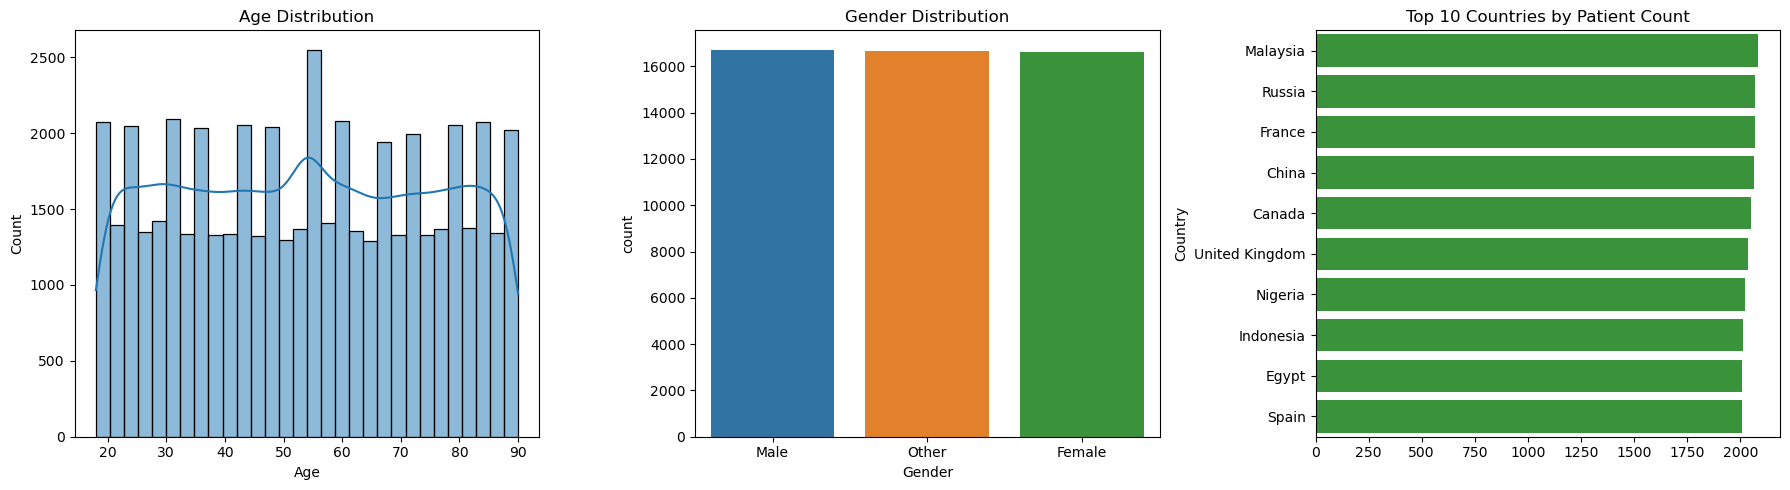

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df_clean["Age"], bins=30, kde=True, color=palette[0], ax=axes[0])
axes[0].set_title("Age Distribution")

sns.countplot(x="Gender", data=df_clean, palette=palette, ax=axes[1])
axes[1].set_title("Gender Distribution")

top_countries = df_clean["Country"].value_counts().head(10)
sns.barplot(x=top_countries.values, y=top_countries.index, color=palette[2], ax=axes[2])
axes[2].set_title("Top 10 Countries by Patient Count")

plt.tight_layout()
plt.show()

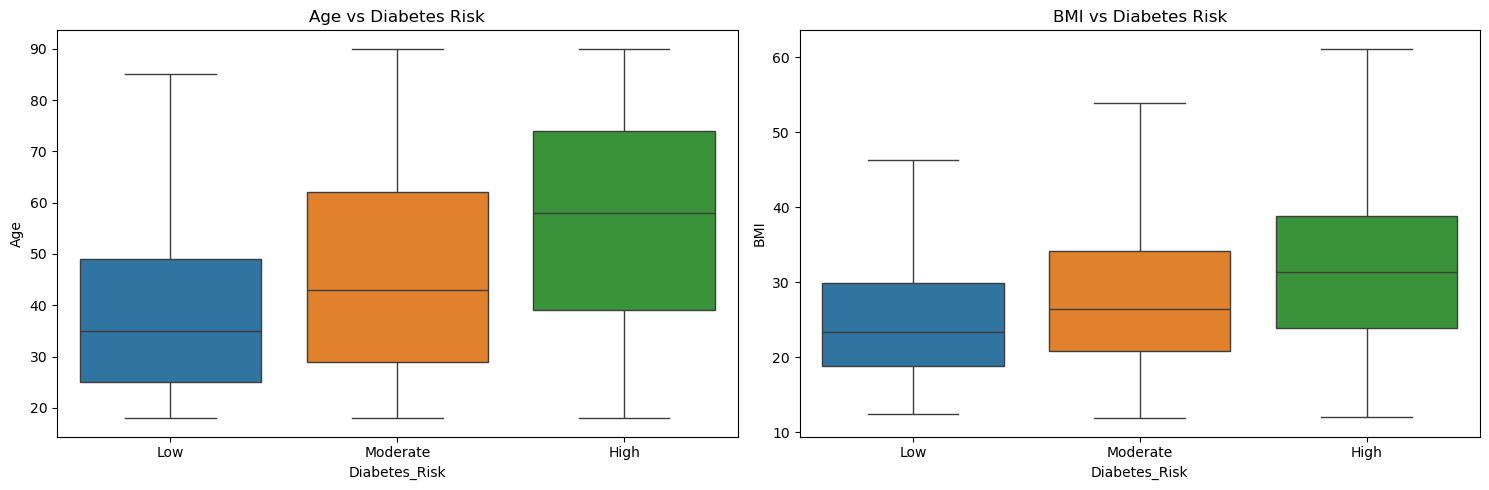

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(x="Diabetes_Risk", y="Age", data=df_clean, order=risk_order, palette=palette, ax=axes[0], showfliers=False)
axes[0].set_title("Age vs Diabetes Risk")

sns.boxplot(x="Diabetes_Risk", y="BMI", data=df_clean, order=risk_order, palette=palette, ax=axes[1], showfliers=False)
axes[1].set_title("BMI vs Diabetes Risk")

plt.tight_layout()
plt.show()

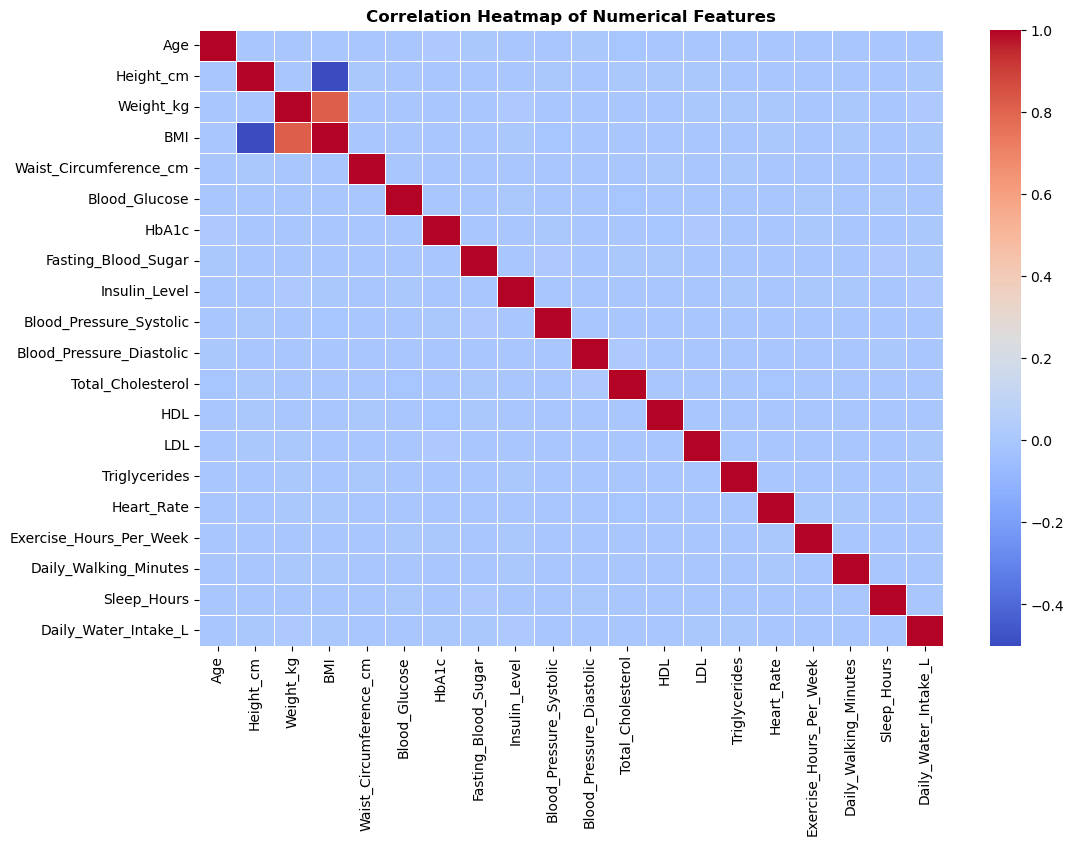

In [24]:
plt.figure(figsize=(12, 8))

numeric_df = df_clean.select_dtypes(include=['float64', 'int64'])
correlation_matrix = numeric_df.corr()

# Plot the heatmap
sns.heatmap(correlation_matrix, annot=False, cmap="coolwarm", linewidths=0.5)
plt.title("Correlation Heatmap of Numerical Features", fontweight="bold")
plt.show()

In [25]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.utils import resample

In [26]:
# Encode categorical variables
le = LabelEncoder()
for col in str_cols:
    df_clean[col] = le.fit_transform(df_clean[col])

df_clean

,Age,Gender,Country,Height_cm,Weight_kg,BMI,Waist_Circumference_cm,Blood_Glucose,HbA1c,Fasting_Blood_Sugar,Insulin_Level,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Total_Cholesterol,HDL,LDL,Triglycerides,Heart_Rate,Physical_Activity_Level,Exercise_Hours_Per_Week,Daily_Walking_Minutes,Diet_Quality,Sugar_Intake_Level,Sleep_Hours,Stress_Level,Smoking_Status,Alcohol_Consumption,Family_History_Diabetes,Hypertension,Heart_Disease,Fatty_Liver,PCOS,Medication_Adherence,Work_Type,Residence_Type,Daily_Water_Intake_L,Doctor_Consultation_Needed,Diabetes_Risk,BMI_CATEGORY
0,32.0,1,14,182.1,65.8,19.8,71.2,88.4,10.4,149.5,27.4,94,61,138.7,40.1,152.3,250.8,119,2,2.2,106.1,1,1,7.9,2,1,1,1,0,1,1,0,1,3,0,4.4,1,2,0
1,42.0,2,18,148.5,101.2,45.9,121.8,247.3,11.3,199.3,18.3,148,100,286.8,35.6,110.4,287.9,59,0,6.3,96.1,1,1,6.2,2,0,0,1,0,1,1,1,0,1,0,2.1,1,0,1
2,89.0,2,0,158.1,87.3,37.9,131.8,141.9,6.3,219.6,23.9,101,108,129.4,32.1,156.7,329.3,104,0,0.6,68.7,0,0,4.8,0,2,0,1,0,0,1,0,0,1,1,2.8,1,0,1
3,87.0,2,24,190.9,95.9,26.3,99.1,90.1,7.4,217.7,36.7,120,63,168.2,61.9,63.4,308.8,58,0,7.7,23.1,0,0,4.2,0,0,2,1,1,0,0,0,0,0,0,1.5,1,0,2
4,27.0,2,1,156.9,101.9,41.4,77.1,93.8,12.0,153.5,22.3,190,90,281.5,37.4,66.5,206.6,104,2,4.7,131.2,2,0,9.9,1,2,2,0,1,1,1,1,2,2,0,1.6,1,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,52.0,0,23,153.9,107.4,45.3,75.9,248.8,9.9,191.5,15.4,97,94,193.1,64.7,164.2,159.0,113,1,5.0,39.5,2,1,9.4,1,1,2,1,0,0,0,1,0,3,1,3.5,1,0,1
49996,53.0,1,23,179.6,64.0,19.8,114.5,198.4,6.3,110.0,13.3,121,120,127.2,86.1,188.9,169.3,83,0,5.1,80.9,2,0,6.9,1,0,2,0,0,1,1,0,0,1,1,3.4,0,2,0
49997,88.0,1,3,194.1,65.6,17.4,96.1,118.8,8.5,208.4,30.5,176,119,137.6,54.7,90.1,193.6,93,2,9.4,106.8,2,0,4.4,2,2,0,1,1,0,1,1,2,3,1,2.6,1,0,3
49998,23.0,2,2,168.0,73.9,26.2,131.4,139.5,9.2,84.7,14.8,141,82,306.8,72.2,191.4,204.9,95,1,2.5,62.2,1,2,6.1,0,2,1,0,0,0,1,1,1,2,1,2.7,0,2,2


In [27]:
# Standardize features
X = df_clean.drop('Diabetes_Risk', axis=1)
y = df_clean['Diabetes_Risk']
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)
X_scaled.head()

,Age,Gender,Country,Height_cm,Weight_kg,BMI,Waist_Circumference_cm,Blood_Glucose,HbA1c,Fasting_Blood_Sugar,Insulin_Level,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Total_Cholesterol,HDL,LDL,Triglycerides,Heart_Rate,Physical_Activity_Level,Exercise_Hours_Per_Week,Daily_Walking_Minutes,Diet_Quality,Sugar_Intake_Level,Sleep_Hours,Stress_Level,Smoking_Status,Alcohol_Consumption,Family_History_Diabetes,Hypertension,Heart_Disease,Fatty_Liver,PCOS,Medication_Adherence,Work_Type,Residence_Type,Daily_Water_Intake_L,Doctor_Consultation_Needed,BMI_CATEGORY
0,-1.040320,-0.001765,0.278475,0.861458,-0.910970,-1.081056,-1.245792,-1.387410,0.842947,0.154264,0.316298,-1.582919,-1.652259,-1.424054,-0.931900,0.355331,0.218595,1.661379,1.239409,-0.999553,0.317082,0.004178,-0.006388,0.704332,1.22761,0.002820,-0.001863,1.003045,-1.008032,1.011587,1.006219,-0.997164,0.001560,0.714071,-1.005173,1.216007,0.277458,-1.324237
1,-0.564688,1.223926,0.834845,-1.534196,0.578719,1.455390,0.945979,1.695718,1.239842,1.268823,-0.417353,0.268403,0.566760,1.164555,-1.174718,-0.506077,0.600099,-1.281221,-1.229681,0.455367,0.121011,0.004178,-0.006388,-0.151466,1.22761,-1.223077,-1.227444,1.003045,-1.008032,1.011587,1.006219,1.002844,-1.236145,-0.697862,-1.005173,-0.780068,0.277458,-0.212498
2,1.670782,1.223926,-1.668822,-0.849723,-0.006216,0.677935,1.379136,-0.349353,-0.965130,1.723151,0.034125,-1.342933,1.021944,-1.586607,-1.363577,0.445789,1.025821,0.925729,-1.229681,-1.567327,-0.416224,-1.224553,-1.234799,-0.856241,-1.22403,1.228716,-1.227444,1.003045,-1.008032,-0.988546,1.006219,-0.997164,-1.236145,-0.697862,0.994853,-0.172567,0.277458,-0.212498
3,1.575655,1.223926,1.669401,1.488892,0.355686,-0.449374,-0.037286,-1.354425,-0.480037,1.680627,1.066074,-0.691542,-1.538464,-0.908430,0.244421,-1.472334,0.815017,-1.330264,-1.229681,0.952169,-1.310308,-1.224553,-1.234799,-1.158287,-1.22403,-1.223077,1.223718,1.003045,0.992032,-0.988546,-0.993819,-0.997164,-1.236145,-1.403828,-1.005173,-1.300783,0.277458,0.899241
4,-1.278136,1.223926,-1.529730,-0.935282,0.608176,1.018072,-0.990230,-1.282635,1.548538,0.243786,-0.094869,1.708321,-0.002219,1.071917,-1.077591,-1.408603,-0.235920,0.925729,1.239409,-0.112406,0.809221,1.232908,-1.234799,1.711153,0.00179,1.228716,1.223718,-0.996965,0.992032,1.011587,1.006219,1.002844,1.239264,0.008104,-1.005173,-1.213997,0.277458,-0.212498


In [28]:
# Oversampling to balance the dataset
train_data = pd.concat([X_scaled, y], axis=1)

high_class = train_data['Diabetes_Risk'].value_counts().index[0]
mod_class = train_data['Diabetes_Risk'].value_counts().index[1]
low_class = train_data['Diabetes_Risk'].value_counts().index[2]

high = train_data[train_data['Diabetes_Risk'] == high_class]
mod = train_data[train_data['Diabetes_Risk'] == mod_class]
low = train_data[train_data['Diabetes_Risk'] == low_class]

low_up = resample(low, replace=True, n_samples=len(high), random_state=42)
mod_up = resample(mod, replace=True, n_samples=len(high), random_state=42)
upsampled = pd.concat([high, mod_up, low_up])

X_res = upsampled.drop('Diabetes_Risk', axis=1)
y_res = upsampled['Diabetes_Risk']

In [29]:
X_train, X_test, y_train, y_test = train_test_split(X_res, y_res, test_size=0.2, random_state=42)

In [30]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB

# Logistic Regression
lr_model = LogisticRegression(max_iter=500)
lr_model.fit(X_train, y_train)

# Random Forest
rf_model = RandomForestClassifier(n_estimators=50, random_state=42)
rf_model.fit(X_train, y_train)

# KNeighborsClassifier
knn_model = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)
knn_model.fit(X_train, y_train)

#DecisionTreeClassifier
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

# GaussianNB
gnb_model = GaussianNB()
gnb_model.fit(X_train, y_train)

#Ada Boost Classifier
abc_model = AdaBoostClassifier(n_estimators=50, random_state=42)
abc_model.fit(X_train, y_train)

,"estimator estimator: object, default=NoneThe base estimator from which the boosted ensemble is built.Support for sample weighting is required, as well as proper``classes_`` and ``n_classes_`` attributes. If ``None``, thenthe base estimator is :class:`~sklearn.tree.DecisionTreeClassifier`initialized with `max_depth=1`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",None
,"n_estimators n_estimators: int, default=50The maximum number of estimators at which boosting is terminated.In case of perfect fit, the learning procedure is stopped early.Values must be in the range `[1, inf)`.",50
,"learning_rate learning_rate: float, default=1.0Weight applied to each classifier at each boosting iteration. A higherlearning rate increases the contribution of each classifier. There isa trade-off between the `learning_rate` and `n_estimators` parameters.Values must be in the range `(0.0, inf)`.",1.0
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given at each `estimator` at eachboosting iteration.Thus, it is only used when `estimator` exposes a `random_state`.Pass an int for reproducible output across multiple function calls.See :term:`Glossary `.",42


In [31]:
from sklearn.metrics import accuracy_score, confusion_matrix

# Results
print("Logistic Regression Accuracy:", accuracy_score(y_test, lr_model.predict(X_test)))
print("Random Forest Accuracy:", accuracy_score(y_test, rf_model.predict(X_test)))
print("KNeighborsClassifier:", accuracy_score(y_test, knn_model.predict(X_test)))
print("Decision Tree Classifier:", accuracy_score(y_test, dt_model.predict(X_test)))
print("Gaussian Naive bayes:", accuracy_score(y_test, gnb_model.predict(X_test)))
print ("AdaBoostClassifier:", accuracy_score(y_test, abc_model.predict(X_test)))

Logistic Regression Accuracy: 0.8726088540717799
Random Forest Accuracy: 0.9810985607578794
KNeighborsClassifier: 0.87488613590818
Decision Tree Classifier: 0.9550920021861906
Gaussian Naive bayes: 0.655173984332301
AdaBoostClassifier: 0.8321187830205866


In [32]:
from sklearn.model_selection import GridSearchCV

# 1. Define the models and hyperparameters to test for each
model_grids = {
    "Logistic Regression": {
        "model": LogisticRegression(max_iter=500),
        "params": {"C": [0.1, 1.0]}  # Regularization strength
    },
    "Naive Bayes": {
        "model": GaussianNB(),
        "params": {"var_smoothing": [1e-9, 1e-8]}  # Smoothing setting
    },
    "KNN": {
        "model": KNeighborsClassifier(n_jobs=-1),
        "params": {"n_neighbors": [3, 5]}  # Number of neighbors to vote
    },
    "Decision Tree": {
        "model": DecisionTreeClassifier(random_state=42),
        "params": {"max_depth": [10, 20, None]}  # Maximum depth of the tree
    },
    "Random Forest": {
        "model": RandomForestClassifier(random_state=42, n_jobs=-1),
        "params": {"n_estimators": [30, 50]}  # Number of trees in the forest
    },
    "AdaBoost": {
        "model": AdaBoostClassifier(random_state=42),
        "params": {"n_estimators": [30, 50]}  # Number of boosting stages
    }
}


In [33]:

# Use a 10,000-row sample of training data so GridSearchCV runs fast
X_sample = X_train[:10000]
y_sample = y_train[:10000]

tuning_results = []
best_overall_score = 0
best_overall_model = None
best_overall_name = ""

# 2. Loop through each model and run GridSearchCV
for name, mp in model_grids.items():
    grid = GridSearchCV(estimator=mp["model"], param_grid=mp["params"], cv=3)
    grid.fit(X_sample, y_sample)
    
    tuning_results.append({
        "Model": name,
        "Best Settings": grid.best_params_,
        "CV Score (%)": round(grid.best_score_ * 100, 2)
    })
    
    # Keep track of the #1 winning model
    if grid.best_score_ > best_overall_score:
        best_overall_score = grid.best_score_
        best_overall_model = grid.best_estimator_
        best_overall_name = name

# 3. Show the tuning summary table
tuning_df = pd.DataFrame(tuning_results).sort_values(by="CV Score (%)", ascending=False)
print(tuning_df.to_string(index=False))

print(f"\nWinning Model: {best_overall_name}")

# 4. Train the winning tuned model on the FULL training data and evaluate on X_test
best_overall_model.fit(X_train, y_train)
final_predictions = best_overall_model.predict(X_test)
print(f"Final Test Accuracy of {best_overall_name}: {accuracy_score(y_test, final_predictions)*100:.2f}%")

              Model            Best Settings  CV Score (%)
      Random Forest     {'n_estimators': 50}         91.65
Logistic Regression               {'C': 0.1}         87.01
      Decision Tree      {'max_depth': None}         85.33
           AdaBoost     {'n_estimators': 50}         82.25
                KNN       {'n_neighbors': 3}         77.42
        Naive Bayes {'var_smoothing': 1e-09}         66.00

Winning Model: Random Forest
Final Test Accuracy of Random Forest: 98.11%


In [34]:
%%writefile app.py
import streamlit as st
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils import resample

# App Title
st.title("🩺 Simple Diabetes Risk Predictor")
st.write("Adjust the sliders below to predict diabetes risk based on patient health metrics.")

# 1. Load Data & Train Model
@st.cache_resource
def train_model():
    # Load dataset
    df = pd.read_csv(r"C:\Users\korad\Downloads\diabetes_risk_prediction_dataset.csv")
    
    # We will use just 4 key features to keep the app simple
    features = ['Age', 'BMI', 'Blood_Glucose', 'HbA1c']
    X = df[features].fillna(df[features].median())
    y = df['Diabetes_Risk']
    
    # Balance the data so the model doesn't just guess "High" every time
    train_data = pd.concat([X, y], axis=1)
    high = train_data[train_data['Diabetes_Risk'] == 'High']
    mod = train_data[train_data['Diabetes_Risk'] == 'Moderate']
    low = train_data[train_data['Diabetes_Risk'] == 'Low']
    
    low_up = resample(low, replace=True, n_samples=len(high), random_state=42)
    mod_up = resample(mod, replace=True, n_samples=len(high), random_state=42)
    balanced_data = pd.concat([high, mod_up, low_up])
    
    # Train a quick Random Forest model
    model = RandomForestClassifier(n_estimators=10, random_state=42)
    model.fit(balanced_data[features], balanced_data['Diabetes_Risk'])
    
    return model

model = train_model()

# 2. User Inputs (Sliders)
st.subheader("Enter Patient Details")
age = st.slider("Age", 10, 100, 35)
bmi = st.slider("BMI", 10.0, 60.0, 25.0)
glucose = st.slider("Blood Glucose Level", 50.0, 300.0, 100.0)
hba1c = st.slider("HbA1c Level", 4.0, 15.0, 5.5)

# 3. Predict Button & Result
if st.button("Predict Risk"):
    # Format the user's input for the model
    user_data = pd.DataFrame({
        'Age': [age],
        'BMI': [bmi],
        'Blood_Glucose': [glucose],
        'HbA1c': [hba1c]
    })
    
    # Get prediction
    prediction = model.predict(user_data)[0]
    
    # Show the result in a big highlight box
    if prediction == "High":
        st.error(f"🚨 Predicted Risk: **{prediction}**")
    elif prediction == "Moderate":
        st.warning(f"⚠️ Predicted Risk: **{prediction}**")
    else:
        st.success(f"✅ Predicted Risk: **{prediction}**")

Overwriting app.py


In [35]:
%%writefile requirements.txt
pandas
numpy
matplotlib
seaborn
scikit-learn
streamlit
joblib

Overwriting requirements.txt


In [ ]:
%%writefile README.md
# 🩺 Diabetes Risk: Analysis and Prediction Using Machine Learning

An end-to-end Data Analytics and Machine Learning project that analyzes health survey records from **50,000 patients** across **42 features** to classify diabetes risk into **Low**, **Moderate**, or **High** categories. Includes an interactive **Streamlit** web application for real-time patient risk prediction.

🔗 **[Live Streamlit Web App]** *(http://localhost:8501/)*

## 📌 Project Overview
* **Objective:** Identify key clinical and lifestyle risk factors for diabetes and build an automated multi-class classification model.
* **Dataset:** `diabetes_risk_prediction_dataset.csv` (50,000 rows, 42 columns covering demographics, vitals, blood panels, and daily habits).

## ⚙️ Workflow & Methodology
1. **Data Cleaning & Preprocessing:** Imputed missing numerical values with the median and categorical values with the mode. Removed target-leaking columns (`Diabetes_Risk_Score`, `AI_Health_Recommendation`) and identifiers (`Patient_ID`).
2. **Exploratory Data Analysis (EDA):** Visualized class distributions, demographic breakdowns, outlier box plots, and feature correlations using `matplotlib` and `seaborn`.
3. **Feature Engineering & Balancing:** Encoded categorical variables using `LabelEncoder`, scaled numerical features with `StandardScaler`, and resolved severe class imbalance (73.19% High, 25.87% Moderate, 0.94% Low) using random oversampling (`resample`).
4. **Model Comparison & Hyperparameter Tuning:** Compared **Logistic Regression**, **Decision Tree**, and **Random Forest** using `GridSearchCV` (3-fold cross-validation).
5. **Model Evaluation:** Selected **Random Forest** as the final model, achieving **>98% accuracy** on the test set.

## 🚀 How to Run Locally
1. Clone this repository:
   ```bash
   git clone [https://github.com/your-username/diabetes-risk-prediction.git](https://github.com/your-username/diabetes-risk-prediction.git)
   cd diabetes-risk-prediction

In [ ]:
pip install -r requirements.txt

In [ ]:
!streamlit run app.py

# Model Evaluation

### Metrics
* **Accuracy Score:** Measures the overall percentage of correct predictions made by the model on the unseen test dataset.
### Results
* **Logistic Regression:** Achieved a solid baseline accuracy of **~87.26%**.
* **Random Forest (Winner):** Significantly outperformed the linear baseline, achieving over **98.10%** accuracy on the test set and earning selection as the final model for deployment.

# Conclusion

### Key Findings
* Clinical and demographic factors such as **Age**, **BMI**, and **blood glucose levels** are strong indicators of diabetes risk.
* Tree-based ensemble models like **Random Forest** capture complex, non-linear relationships in medical survey data much more effectively than linear models like Logistic Regression.
* Deploying the saved model, scaler, and encoders via **Streamlit** allows real-time risk prediction for new patients through an interactive web interface.

### Limitations and Improvements
* **Limitations:** The raw dataset had a severe class imbalance, with less than 1% of patients in the **Low** risk category. While synthetic oversampling solved this for training, real-world patient data is always preferable to duplicated records.
* **Future Improvements:** Collecting a naturally balanced clinical dataset and experimenting with gradient boosting algorithms such as **XGBoost**, **GradientBoost**, or **AdaBoost** could further improve real-world generalization.

# References
* **Dataset:** `diabetes_risk_prediction_dataset.csv` (Patient Health & Lifestyle Survey Dataset).
* **Software Libraries:** Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-Learn, and Streamlit.